In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Tue Jun  7 12:02:15 2022

@author: sunms498
"""

'\nCreated on Tue Jun  7 12:02:15 2022\n\n@author: sunms498\n'

## Load libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from os import walk
import pickle
from pathlib import Path
from shapely.geometry import Point
import geopandas as gpd
from geopandas import GeoDataFrame
import matplotlib.colors as colors
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from pathlib import Path
from matplotlib.colors import LogNorm
import cmcrameri.cm as cmc
import cmocean as cmo
ds=2.6 #bulk density of marine soil

/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/xarray/backends/cfgrib_.py:27: UserWarning: Failed to load cfgrib - most likely there is a problem accessing the ecCodes library. Try `import cfgrib` to get the full error message
  warnings.warn(


## Load data

In [25]:
#Load prediction maps and uncertainty maps from the monte carlo dropout for both continental shelves and deep ocean models

filename = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/prediction_map_SedRate_CS_supervised.npy"
prediction_map_CS = np.load(filename)
prediction_map_DO = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/prediction_map_SedRate_DO_supervised.npy")

#filename = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/uncertainty_map_TOC_supervised_men_CS_noconstraint.npy"
#uncertainty_map_CS = np.load(filename)
#uncertainty_map_DO = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/uncertainty_map_TOC_noconstraint_supervised_men_DO.npy")

In [26]:
# Overlap both the deep ocean and the continental shelves
# pm: prediction map, um_uncertaintymap
dataset_mask = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/masks/mask_deepocean.npy")
dataset_mask = np.rot90(np.rot90(np.fliplr(dataset_mask)))

# Create a copy of pm_CS
pm_overlapped = np.copy(prediction_map_DO)

# Mask the values from pm_CS where mask contains NaN values
pm_overlapped[np.isnan(dataset_mask)] = prediction_map_CS[np.isnan(dataset_mask)]
"""
# Create a copy of pm_CS
um_overlapped = np.copy(uncertainty_map_DO)

# Mask the values from pm_CS where mask contains NaN values
um_overlapped[np.isnan(dataset_mask)] = uncertainty_map_CS[np.isnan(dataset_mask)]
"""

'\n# Create a copy of pm_CS\num_overlapped = np.copy(uncertainty_map_DO)\n\n# Mask the values from pm_CS where mask contains NaN values\num_overlapped[np.isnan(dataset_mask)] = uncertainty_map_CS[np.isnan(dataset_mask)]\n'

In [27]:
#load porosity file

file_porosity = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/porosity/grl53425-sup-0002-supinfo.grd"
#file_porosity = "file_porosity = "/home/sunms498/Data/paper_porosity/GPSM_Restreppo/prediction.nc""
rootgrp_porosity = xr.open_dataset(Path(file_porosity), format = 'NETCDF4')
                                                                   
dataset_porosity = rootgrp_porosity.variables['z']

dataset_numpy_porosity = dataset_porosity.to_numpy()
dataset_numpy_porosity = np.rot90(np.rot90(np.fliplr(dataset_numpy_porosity)))

In [28]:

# make area of the cells file, based on the latitude


restrepo_features_path = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/GL_LATITUDE_DD.5m.nc"
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    restrepo_files.extend(filenames)

restrepo_files.sort()
len(restrepo_files)

rootgrp = xr.open_dataset(restrepo_features_path, format = 'NETCDF4')
latitudes = rootgrp.variables['lat']
longitudes = rootgrp.variables['lon']


file_idx = -1
corrupted_files = 0

rootgrp = xr.open_dataset(restrepo_features_path, format = 'NETCDF4')

dataset = rootgrp.variables['data']
area = 9.297**2 * np.cos(dataset/180 * np.pi) # in km2

In [29]:
# overlay land boundaries on the prediction and uncertainty maps

land_file = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/island_map.npy")
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1


pm_overlapped[land_map] = np.nan
#um_overlapped[land_map] = np.nan

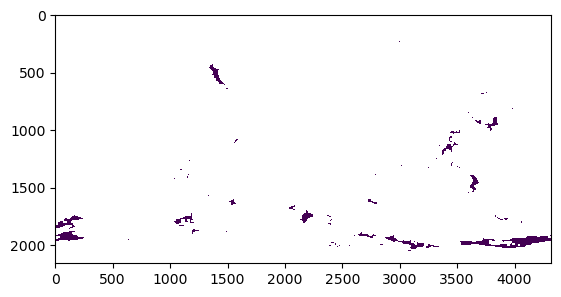

In [30]:
dataset_mask = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/masks/mask_continentalshelves.npy")
plt.imshow(dataset_mask)

## Visualise

In [31]:
def VisualiseMap(data, cmap, use_log_norm=False, vmin=None, vmax=None, cbar_label = None):
    """
    Visualize a map using matplotlib.

    Parameters:
        data (numpy.ndarray): Array containing the data to be visualized.
        cmap (str or matplotlib.colors.Colormap): Colormap to be used for visualization.
        use_log_norm (bool): Whether to use logarithmic normalization for color scaling.
        vmin (float): Minimum value for color scaling.
        vmax (float): Maximum value for color scaling.
    """
    plt.figure(figsize=(20, 10), dpi=300)
    
    if use_log_norm:
        norm = LogNorm(vmin=vmin, vmax=vmax)
        plt.imshow(data, cmap=cmap, norm=norm, extent=[-180, 180, -90, 90])
    else:
        norm = None
        plt.imshow(data, cmap=cmap, vmax = vmax, vmin = vmin, extent=[-180, 180, -90, 90])
    
    
    
    cbar_label = cbar_label
    
    cbar = plt.colorbar(label=cbar_label, aspect=40, pad=0.01, shrink=0.8)
    cbar.ax.tick_params(labelsize=20)
    cbar.set_label(cbar_label, fontsize=20)
    
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=20)
    plt.xlabel("Longitude", fontsize=20)
    plt.ylabel("Latitude", fontsize=20)
    plt.tight_layout()
    
    plt.show()

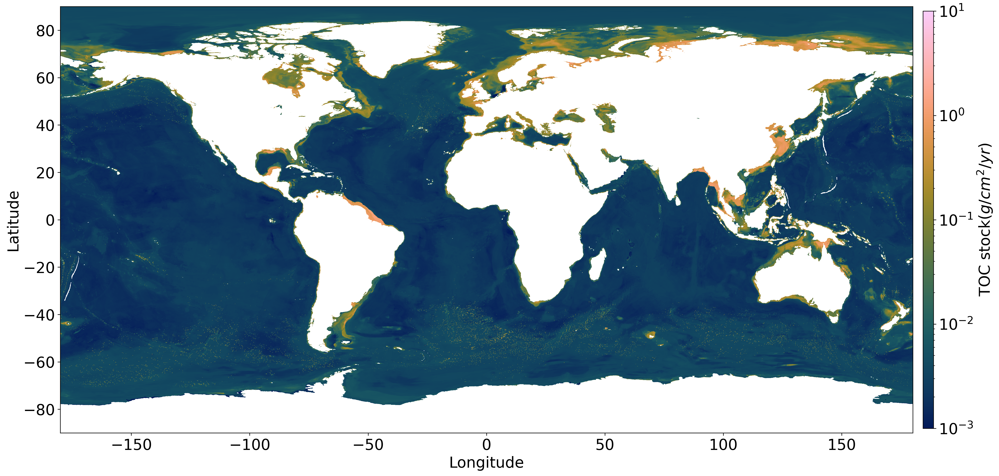

In [42]:
tocGlobal = (1-(dataset_numpy_porosity/100))*ds*(pm_overlapped/1e3)
VisualiseMap(tocGlobal, cmc.batlow, use_log_norm=True, vmin=1e-3, vmax=1e1, cbar_label= "TOC stock($g/cm^2/yr$)")

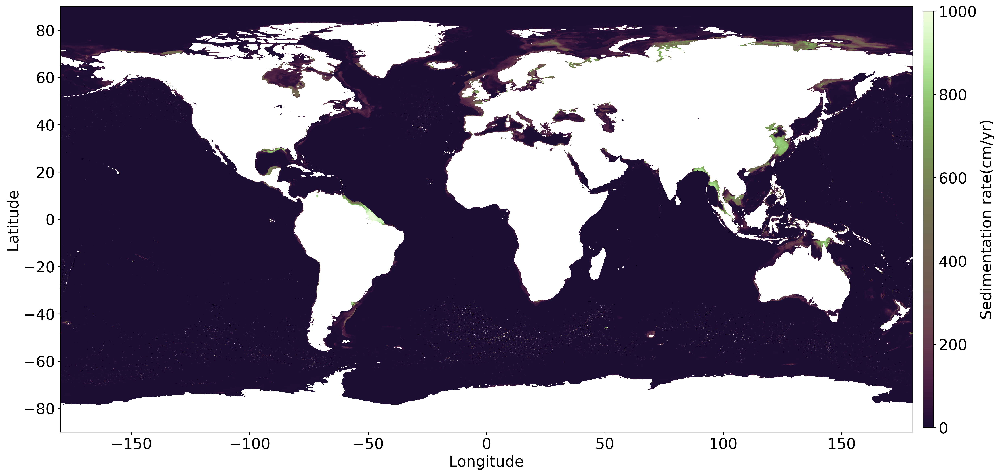

In [33]:
VisualiseMap(pm_overlapped, cmap=cmc.tokyo, use_log_norm=False, vmin=0, vmax=1000, cbar_label= "Sedimentation rate(cm/yr)")

In [43]:
np.save("/gxfs_work/cau/sunms498/work/toc-infoshap/data/output/marGlobal.npy", tocGlobal)

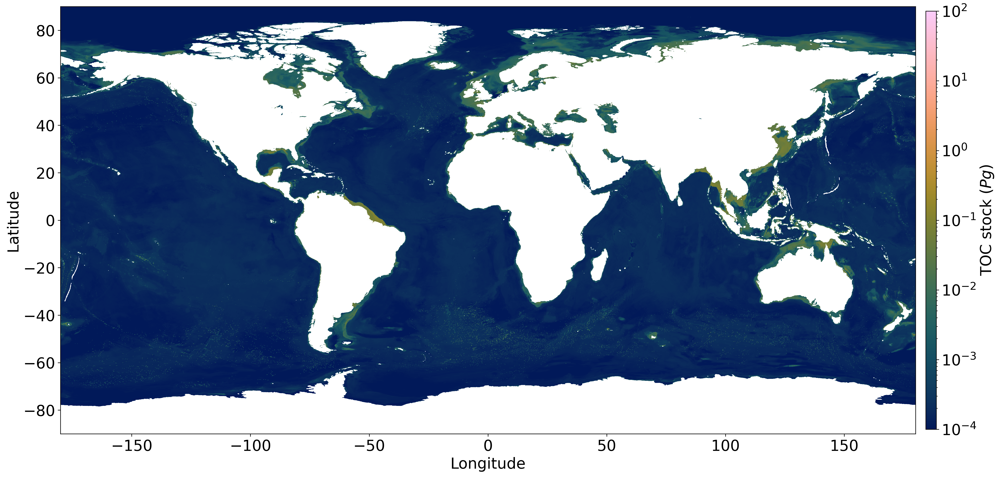

In [36]:
area_np = np.array(area) # in km²:  10¹⁰ cm² = 1 km²
tocGlobal_g = np.multiply(tocGlobal,area_np)*1e10 # in g

VisualiseMap(tocGlobal_g/1e15, cmap=cmc.batlow, use_log_norm=True, vmin=1e-4, vmax=1e2, cbar_label= "TOC stock ($Pg$)")

In [51]:
area_np = np.array(area) # in km²:  10¹⁰ cm² = 1 km²

area_np_land = area_np
area_np_land[land_map]= 0
#VisualiseMap(area_np_land, cmap=cmc.oslo, vmax=90, cbar_label='Cell area ($km^2$)')

In [52]:
tocPercent_cellwise = np.multiply(pm_overlapped,area_np) # in % km²
#VisualiseMap(tocPercent_cellwise, cmap=cmo.cm.haline, use_log_norm=True,vmin=1e1, vmax=1e3, cbar_label= "TOC concentration (%)")

## Analyse

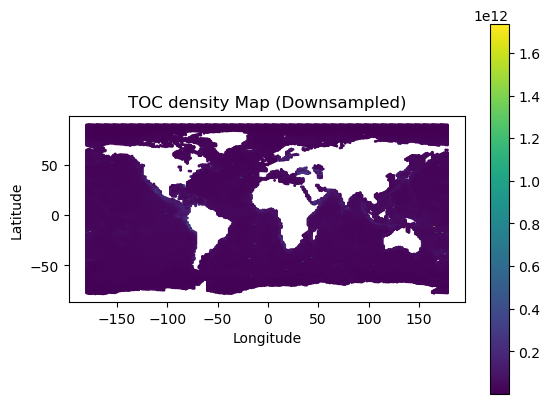

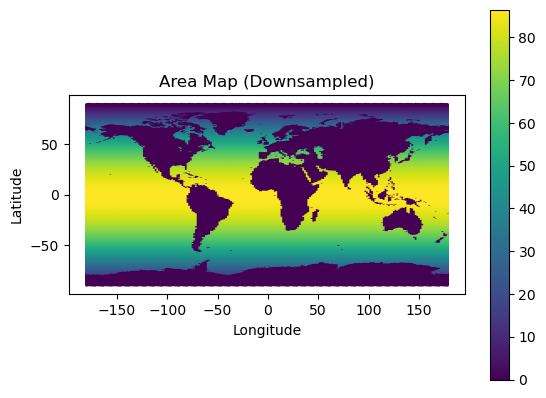

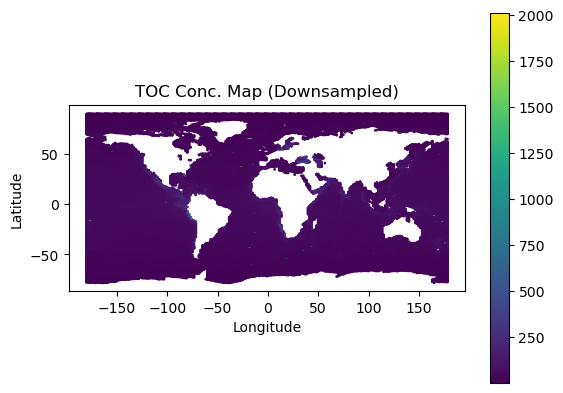

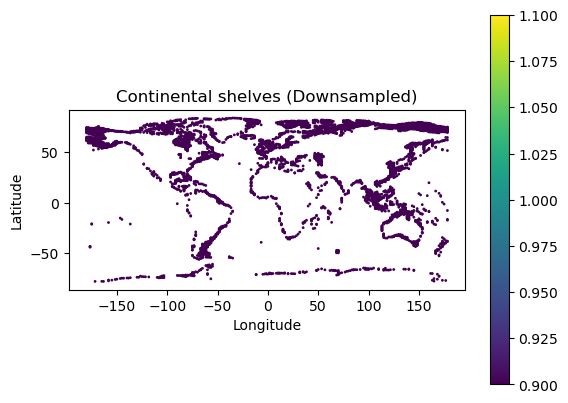

In [53]:
# Make geo dataframes and plot them
import geopandas as gpd
from rasterio.features import geometry_mask
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm


resolution = 5 / 60  # 5 arc minutes in degrees
lon = np.arange(-180, 180, resolution)
lat = np.arange(-90, 90, resolution)


tocPercent_cellwise_rot = np.rot90(np.rot90(np.fliplr(tocPercent_cellwise)))
area_np_land_rot = np.rot90(np.rot90(np.fliplr(area_np_land)))
tocGlobal_g_rot = np.rot90(np.rot90(np.fliplr(tocGlobal_g)))
continentalshelves_mask = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/masks/mask_continentalshelves.npy")
#continentalshelves_mask_rot = np.rot90(np.rot90(np.fliplr(continentalshelves_mask)))

# Create a GeoDataFrame with the prediction values and their corresponding geometry
lon_mesh, lat_mesh = np.meshgrid(lon, lat)
tocPercentcCellwise_gdf = gpd.GeoDataFrame(
    data={'TOCPercent': tocPercent_cellwise_rot.flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)
prediction_gdf = gpd.GeoDataFrame(
    data={'TOC': tocGlobal_g_rot.flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)
area_gdf = gpd.GeoDataFrame(
    data={'area': np.array(area_np_land_rot).flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)
continentalshelves_gdf = gpd.GeoDataFrame(
    data={'continentalshelves': np.array(continentalshelves_mask).flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)


# Downsample the GeoDataFrame by taking every nth point
n = 100  # Adjust this value based on your desired level of downsampling
downsampled_gdf = prediction_gdf.iloc[::n, :]

# Plot the downsampled GeoDataFrame
downsampled_gdf.plot(column='TOC', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('TOC density Map (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

downsampled_gdf = area_gdf.iloc[::n, :]

# Plot the downsampled GeoDataFrame
downsampled_gdf.plot(column='area', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('Area Map (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

downsampled_gdf = tocPercentcCellwise_gdf.iloc[::n, :]

downsampled_gdf.plot(column='TOCPercent', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('TOC Conc. Map (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

downsampled_gdf = continentalshelves_gdf.iloc[::n, :]

downsampled_gdf.plot(column='continentalshelves', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('Continental shelves (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

,name,latitude,longitude,min_Y,min_X,max_Y,max_X,area_km2,geometry
0,Southern Ocean,-68.03985,-26.63275,-85.56250,-180.00000,-60.00000,180.00000,6793589,"POLYGON ((180.00000 -60.00000, 180.00000 -84.3..."
1,South Atlantic Ocean,-33.73758,-18.83411,-60.00000,-69.60084,0.07511,20.00000,42815540,"MULTIPOLYGON (((-50.68008 0.00000, -50.64339 0..."
2,South Pacific Ocean,-30.09612,-143.06088,-60.00000,130.11129,3.39114,-67.26667,90147400,"MULTIPOLYGON (((-70.93199 -54.75580, -70.92427..."
3,North Pacific Ocean,26.95013,-169.38334,0.00000,117.51622,66.56286,-76.98544,77124830,"MULTIPOLYGON (((157.14844 57.76842, 157.15257 ..."
4,South China and Easter Archipelagic Seas,5.62943,115.46548,-10.92259,95.43328,25.56728,134.03155,6822162,"MULTIPOLYGON (((119.28261 25.48829, 119.27451 ..."
5,Indian Ocean,-27.27272,79.60241,-60.00000,20.00000,31.18586,146.91671,78162363,"MULTIPOLYGON (((56.08700 27.10831, 56.08874 27..."
6,Mediterranean Region,38.13065,19.70067,30.06809,-6.03255,47.37640,42.35496,2988248,"POLYGON ((32.57319 30.06809, 32.56996 30.06817..."
7,Baltic Sea,58.78478,19.22115,52.65352,9.36560,67.08059,30.34710,415600,"POLYGON ((27.35543 60.48886, 27.35988 60.48797..."
8,North Atlantic Ocean,31.77621,-40.24758,-0.93603,-98.05392,68.63872,12.00594,41741693,"MULTIPOLYGON (((-29.42622 68.22895, -23.13435 ..."
9,Arctic Ocean,79.14792,-3.28568,51.14359,-180.00000,90.00000,180.00000,15571669,"MULTIPOLYGON (((178.29612 69.42748, 178.29961 ..."


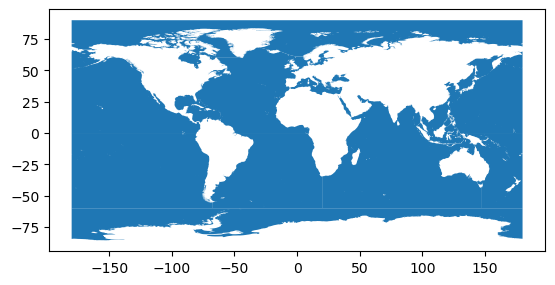

In [54]:
ocean_gdf = gpd.read_file('/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/GOaS_v1_20211214/goas_v01.shp')
ocean_gdf.plot()
ocean_gdf

In [55]:
# Find the sum of TOC stock, TOC Percent and area in each ocean region
joined_gdf = gpd.sjoin(prediction_gdf, ocean_gdf, predicate='within')
joined_area_gdf = gpd.sjoin(area_gdf, ocean_gdf, predicate='within')
joined_gdf_tocPercent = gpd.sjoin(tocPercentcCellwise_gdf, ocean_gdf, predicate='within')

In [56]:
# Calculate the sum of TOC in each polygon
sum_toc_by_polygon = (joined_gdf.groupby('name')['TOC']).sum()

# Print the sum of TOC in each polygon
for ocean_name, toc_sum in sum_toc_by_polygon.items():
    print(f"Sum of TOC  in {ocean_name}: {toc_sum/1e15} Pg")

Sum of TOC  in Arctic Ocean: 12.217038190380666 Pg
Sum of TOC  in Baltic Sea: 0.8404742125136337 Pg
Sum of TOC  in Indian Ocean: 32.34517572508457 Pg
Sum of TOC  in Mediterranean Region: 2.762550608040676 Pg
Sum of TOC  in North Atlantic Ocean: 19.620813077402392 Pg
Sum of TOC  in North Pacific Ocean: 36.33577145266614 Pg
Sum of TOC  in South Atlantic Ocean: 16.624558570925497 Pg
Sum of TOC  in South China and Easter Archipelagic Seas: 4.211153630019358 Pg
Sum of TOC  in South Pacific Ocean: 37.91271689315057 Pg
Sum of TOC  in Southern Ocean: 7.828277184581835 Pg


In [57]:
# Calculate the sum of TOC Percent weighted by the area of the cells in each polygon
sum_toc_by_polygon = (joined_gdf_tocPercent.groupby('name')['TOCPercent']).sum()

# Print the sum of TOC in each polygon
for ocean_name, toc_sum in sum_toc_by_polygon.items():
    print(f"Sum of TOC Percent in {ocean_name}: {toc_sum/1e6} %km2 (x1e6)")

Sum of TOC Percent in Arctic Ocean: 13.315903332332743 %km2 (x1e6)
Sum of TOC Percent in Baltic Sea: 1.3203352895834106 %km2 (x1e6)
Sum of TOC Percent in Indian Ocean: 45.43502968468842 %km2 (x1e6)
Sum of TOC Percent in Mediterranean Region: 3.309049574595362 %km2 (x1e6)
Sum of TOC Percent in North Atlantic Ocean: 27.10807830591804 %km2 (x1e6)
Sum of TOC Percent in North Pacific Ocean: 55.94043351197328 %km2 (x1e6)
Sum of TOC Percent in South Atlantic Ocean: 25.210802411855052 %km2 (x1e6)
Sum of TOC Percent in South China and Easter Archipelagic Seas: 4.7320754645333665 %km2 (x1e6)
Sum of TOC Percent in South Pacific Ocean: 55.254969137085936 %km2 (x1e6)
Sum of TOC Percent in Southern Ocean: 10.726526693726335 %km2 (x1e6)


In [58]:
# Calculate the area in each polygon
area_by_polygon = (joined_area_gdf.groupby('name')['area']).sum()

# Print the sum of TOC in each polygon
for ocean_name, area in area_by_polygon.items():
    print(f"Area of {ocean_name}: {area/1e6} million km^2")

Area of Arctic Ocean: 15.185819 million km^2
Area of Baltic Sea: 0.392735125 million km^2
Area of Indian Ocean: 71.160768 million km^2
Area of Mediterranean Region: 2.91881925 million km^2
Area of North Atlantic Ocean: 41.721284 million km^2
Area of North Pacific Ocean: 77.248968 million km^2
Area of South Atlantic Ocean: 40.530364 million km^2
Area of South China and Easter Archipelagic Seas: 6.7387235 million km^2
Area of South Pacific Ocean: 85.270424 million km^2
Area of Southern Ocean: 20.73395 million km^2


In [59]:
# Calculate the mean TOC percent for each polygon
mean_toc_percent_by_polygon = sum_toc_by_polygon / area_by_polygon

# Print the mean TOC percent in each polygon
for ocean_name, mean_toc_percent in mean_toc_percent_by_polygon.items():
    print(f"Mean TOC Percent in {ocean_name}: {mean_toc_percent} %")

Mean TOC Percent in Arctic Ocean: 0.8768643516910575 %
Mean TOC Percent in Baltic Sea: 3.361897639238178 %
Mean TOC Percent in Indian Ocean: 0.6384842513881867 %
Mean TOC Percent in Mediterranean Region: 1.1336945837243475 %
Mean TOC Percent in North Atlantic Ocean: 0.6497421868875857 %
Mean TOC Percent in North Pacific Ocean: 0.724157680811649 %
Mean TOC Percent in South Atlantic Ocean: 0.6220226004349493 %
Mean TOC Percent in South China and Easter Archipelagic Seas: 0.7022213427414504 %
Mean TOC Percent in South Pacific Ocean: 0.6479968850288107 %
Mean TOC Percent in Southern Ocean: 0.5173412057869501 %


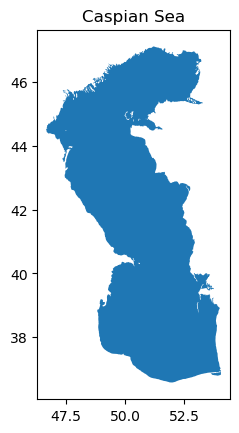

TOC stock inside the Caspian Sea: 0.807683548139748 Pg
Area inside the Caspian Sea: 0.37953628125 million km^2
TOC Percent inside the Caspian Sea: 0.9664313477501629 % (1e6)
Mean TOC Percent inside the Caspian Sea: 2.546347728778994 % 


In [60]:
caspian_sea_gdf = gpd.read_file('worldglwd1.shp')
caspian_sea_gdf.plot()
plt.title('Caspian Sea')
plt.show()
# Reproject caspian_sea_gdf to EPSG:4326
caspian_sea_gdf = caspian_sea_gdf.to_crs(epsg=4326)

# Perform spatial join
joined_gdf_caspian = gpd.sjoin(prediction_gdf, caspian_sea_gdf, how="left", predicate="within")
joined_gdf_caspian_tocPercent = gpd.sjoin(tocPercentcCellwise_gdf, caspian_sea_gdf, predicate='within')
joined_gdf_caspian_area = gpd.sjoin(area_gdf, caspian_sea_gdf, how="left", predicate="within")

# Check the TOC values inside and outside the Caspian Sea
toc_inside_caspian = np.nansum(joined_gdf_caspian[joined_gdf_caspian['lake_name'].notna()]['TOC'])
toc_outside_caspian = np.nansum(joined_gdf_caspian[joined_gdf_caspian['lake_name'].isna()]['TOC'])

print(f"TOC stock inside the Caspian Sea: {toc_inside_caspian/1e15} Pg")
#print(f"TOC stock outside the Caspian Sea: {toc_outside_caspian/1e15} Gt")

# Perform spatial join

# Check the TOC values inside and outside the Caspian Sea
area_inside_caspian = np.nansum(joined_gdf_caspian_area[joined_gdf_caspian_area['lake_name'].notna()]['area'])
area_outside_caspian = np.nansum(joined_gdf_caspian_area[joined_gdf_caspian_area['lake_name'].isna()]['area'])

print(f"Area inside the Caspian Sea: {area_inside_caspian/1e6} million km^2")
#print(f"Area outside the Caspian Sea: {area_outside_caspian/1e6} million km^2")

# Check the TOC values inside and outside the Caspian Sea
tocPercent_inside_caspian = np.nansum(joined_gdf_caspian_tocPercent[joined_gdf_caspian_tocPercent['lake_name'].notna()]['TOCPercent'])
tocPercent_outside_caspian = np.nansum(joined_gdf_caspian_tocPercent[joined_gdf_caspian_tocPercent['lake_name'].isna()]['TOCPercent'])

print(f"TOC Percent inside the Caspian Sea: {tocPercent_inside_caspian/1e6} % (1e6)")
print(f"Mean TOC Percent inside the Caspian Sea: {tocPercent_inside_caspian/area_inside_caspian} % ")



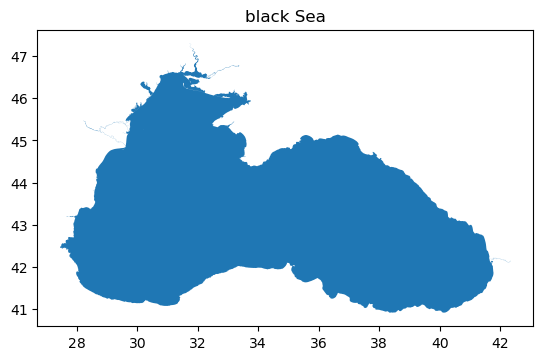

In [ ]:
black_sea_gdf = gpd.read_file('iho/iho.shp')
black_sea_gdf.plot()
plt.title('black Sea')
plt.show()
# Reproject black_sea_gdf to EPSG:4326
black_sea_gdf = black_sea_gdf.to_crs(epsg=4326)

# Perform spatial join
joined_gdf_black = gpd.sjoin(prediction_gdf, black_sea_gdf, how="left", predicate="within")
joined_gdf_black_tocPercent = gpd.sjoin(tocPercentcCellwise_gdf, black_sea_gdf, predicate='within')
joined_gdf_black_area = gpd.sjoin(area_gdf, black_sea_gdf, how="left", predicate="within")

# Check the TOC values inside and outside the black Sea
toc_inside_black = np.nansum(joined_gdf_black[joined_gdf_black['name'].notna()]['TOC'])
toc_outside_black = np.nansum(joined_gdf_black[joined_gdf_black['name'].isna()]['TOC'])

print(f"TOC stock inside the black Sea: {toc_inside_black/1e15} Pg")
#print(f"TOC stock outside the black Sea: {toc_outside_black/1e15} Gt")

# Perform spatial join

# Check the TOC values inside and outside the black Sea
area_inside_black = np.nansum(joined_gdf_black_area[joined_gdf_black_area['name'].notna()]['area_left'])
area_outside_black = np.nansum(joined_gdf_black_area[joined_gdf_black_area['name'].isna()]['area_left'])

print(f"Area inside the black Sea: {area_inside_black/1e6} million km^2")
#print(f"Area outside the black Sea: {area_outside_black/1e6} million km^2")

# Check the TOC values inside and outside the black Sea
tocPercent_inside_black = np.nansum(joined_gdf_black_tocPercent[joined_gdf_black_tocPercent['name'].notna()]['TOCPercent'])
tocPercent_outside_black = np.nansum(joined_gdf_black_tocPercent[joined_gdf_black_tocPercent['name'].isna()]['TOCPercent'])

print(f"TOC Percent inside the black Sea: {tocPercent_inside_black/1e6} % (1e6)")
print(f"Mean TOC Percent inside the black Sea: {tocPercent_inside_black/area_inside_black} % ")



In [ ]:
joined_gdf_black_area 

In [ ]:
black_sea_gdf

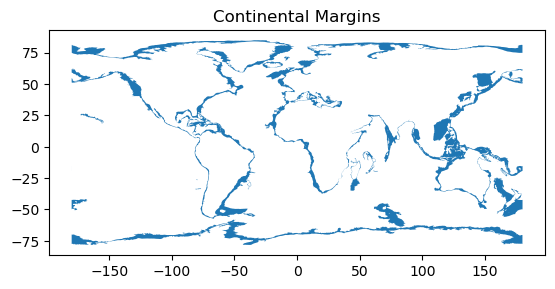

In [68]:
comarge_gdf = gpd.read_file('/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/Comarge/ContinentalMargins.shp')

# Plot the GeoDataFrame
comarge_gdf.plot()
plt.title('Continental Margins')
plt.show()

In [69]:
"""
regions_not_included_gdf = gpd.overlay(ocean_gdf, comarge_gdf, how='difference')

# Plot the regions not included in continental margins
regions_not_included_gdf.plot()
plt.title('Regions Not Included in Continental Margins')
plt.show()
"""

"\nregions_not_included_gdf = gpd.overlay(ocean_gdf, comarge_gdf, how='difference')\n\n# Plot the regions not included in continental margins\nregions_not_included_gdf.plot()\nplt.title('Regions Not Included in Continental Margins')\nplt.show()\n"

In [70]:
"""
#overlay is an expensive process
continental_margins_df = gpd.overlay(ocean_gdf, comarge_gdf, how="intersection")
# Filter the results to keep only the relevant columns
continental_margins_df = continental_margins_df[["name", "geometry"]]

"""

'\n#overlay is an expensive process\ncontinental_margins_df = gpd.overlay(ocean_gdf, comarge_gdf, how="intersection")\n# Filter the results to keep only the relevant columns\ncontinental_margins_df = continental_margins_df[["name", "geometry"]]\n\n'

In [71]:
"""
projected_crs = 'EPSG:4326'

# Reproject the geometries to the new CRS
ocean_gdf_projected = ocean_gdf.to_crs(projected_crs)
# Calculate the area and add a new column
ocean_gdf['polygon_area'] = ocean_gdf_projected['geometry'].area
# Assuming continental_shelves_df is a GeoDataFrame
continental_margins_gdf = gpd.GeoDataFrame(continental_margins_df)

# Plot the GeoDataFrame
continental_margins_gdf.plot(column='name', figsize=(10, 8), cmap='viridis')
plt.title('Continental margins in each ocean')
plt.show()

# Save the GeoDataFrame to a shapefile
continental_margins_gdf.to_file("continental_margins_separate_ocean.shp")
"""

'\nprojected_crs = \'EPSG:4326\'\n\n# Reproject the geometries to the new CRS\nocean_gdf_projected = ocean_gdf.to_crs(projected_crs)\n# Calculate the area and add a new column\nocean_gdf[\'polygon_area\'] = ocean_gdf_projected[\'geometry\'].area\n# Assuming continental_shelves_df is a GeoDataFrame\ncontinental_margins_gdf = gpd.GeoDataFrame(continental_margins_df)\n\n# Plot the GeoDataFrame\ncontinental_margins_gdf.plot(column=\'name\', figsize=(10, 8), cmap=\'viridis\')\nplt.title(\'Continental margins in each ocean\')\nplt.show()\n\n# Save the GeoDataFrame to a shapefile\ncontinental_margins_gdf.to_file("continental_margins_separate_ocean.shp")\n'

In [72]:
import geopandas as gpd
import numpy as np

# Assuming prediction_gdf and comarge_gdf are your GeoDataFrames
# Ensure both GeoDataFrames have the same coordinate reference system (CRS)

# Perform spatial join
joined_gdf = gpd.sjoin(prediction_gdf, comarge_gdf, how="left", predicate="within")
# Check the TOC values inside and outside the continental shelves
toc_inside = np.nansum(joined_gdf[~np.isnan(joined_gdf['Area'])]['TOC'])
toc_outside = np.nansum(joined_gdf[np.isnan(joined_gdf['Area'])]['TOC'])

print(f"Sum of TOC inside continental margins: {toc_inside/1e15} Gt")
print(f"Sum of TOC outside continental margins: {toc_outside/1e15} Gt")

Sum of TOC inside continental margins: 29.64360248589977 Gt
Sum of TOC outside continental margins: 126.92777862309569 Gt


In [73]:
ocean_comarge_gdf = gpd.read_file('continental_shelves_separate_ocean.shp')
# Perform a spatial join to associate each point with the corresponding polygon
joined_gdf = gpd.sjoin(prediction_gdf, ocean_comarge_gdf, predicate='within')
joined_area_gdf = gpd.sjoin(area_gdf, ocean_comarge_gdf, predicate='within')
# Perform a spatial join to associate each point with the corresponding polygon
joined_gdf_TOCPercent = gpd.sjoin(tocPercentcCellwise_gdf, ocean_comarge_gdf, predicate='within')

<Axes: >

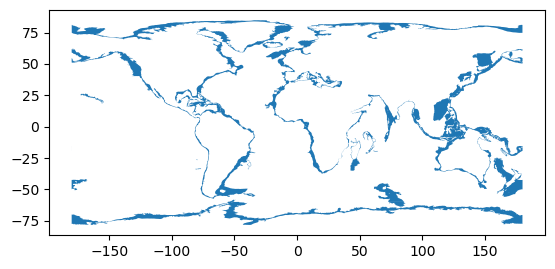

In [74]:
ocean_comarge_gdf.plot()

In [75]:
# Calculate the sum of TOC in each polygon
sum_toc_by_polygon = (joined_gdf.groupby('name')['TOC']).sum()

# Print the sum of TOC in each polygon
for ocean_name, toc_sum in sum_toc_by_polygon.items():
    print(f"Sum of TOC in continental shelves of {ocean_name}: {toc_sum/1e15} Pg")

Sum of TOC in continental shelves of Arctic Ocean: 2.626591500119938 Pg
Sum of TOC in continental shelves of Indian Ocean: 5.390828116140127 Pg
Sum of TOC in continental shelves of Mediterranean Region: 0.6156367736107455 Pg
Sum of TOC in continental shelves of North Atlantic Ocean: 4.017439200153406 Pg
Sum of TOC in continental shelves of North Pacific Ocean: 5.721140106490519 Pg
Sum of TOC in continental shelves of South Atlantic Ocean: 2.453454044122358 Pg
Sum of TOC in continental shelves of South China and Easter Archipelagic Seas: 2.8216021574466 Pg
Sum of TOC in continental shelves of South Pacific Ocean: 4.525643046065335 Pg
Sum of TOC in continental shelves of Southern Ocean: 1.4593917216691832 Pg


In [76]:
# Calculate the sum of TOC in each polygon
sum_toc_by_polygon = (joined_gdf_TOCPercent.groupby('name')['TOCPercent']).sum()

# Print the sum of TOC in each polygon
for ocean_name, toc_sum in sum_toc_by_polygon.items():
    print(f"Sum of TOC % in continental shelves of {ocean_name}: {toc_sum/1e6} %km^2 (1e6)")

Sum of TOC % in continental shelves of Arctic Ocean: 2.764785697585321 %km^2 (1e6)
Sum of TOC % in continental shelves of Indian Ocean: 6.462392337149819 %km^2 (1e6)
Sum of TOC % in continental shelves of Mediterranean Region: 0.6780661449098935 %km^2 (1e6)
Sum of TOC % in continental shelves of North Atlantic Ocean: 4.818102567776114 %km^2 (1e6)
Sum of TOC % in continental shelves of North Pacific Ocean: 7.057675332548423 %km^2 (1e6)
Sum of TOC % in continental shelves of South Atlantic Ocean: 3.6164533802561087 %km^2 (1e6)
Sum of TOC % in continental shelves of South China and Easter Archipelagic Seas: 3.4508253979909025 %km^2 (1e6)
Sum of TOC % in continental shelves of South Pacific Ocean: 5.502690866689478 %km^2 (1e6)
Sum of TOC % in continental shelves of Southern Ocean: 1.7843721865174305 %km^2 (1e6)


In [77]:
# Calculate the sum of TOC in each polygon
area_by_polygon = (joined_area_gdf.groupby('name')['area']).sum()

# Print the sum of TOC in each polygon
for ocean_name, area in area_by_polygon.items():
    print(f"Area of continental shelves in {ocean_name}: {area/1e6} million km^2")

Area of continental shelves in Arctic Ocean: 3.0994685 million km^2
Area of continental shelves in Indian Ocean: 6.6865885 million km^2
Area of continental shelves in Mediterranean Region: 1.101147375 million km^2
Area of continental shelves in North Atlantic Ocean: 6.172802 million km^2
Area of continental shelves in North Pacific Ocean: 6.013555 million km^2
Area of continental shelves in South Atlantic Ocean: 3.4202435 million km^2
Area of continental shelves in South China and Easter Archipelagic Seas: 4.0917005 million km^2
Area of continental shelves in South Pacific Ocean: 5.7994005 million km^2
Area of continental shelves in Southern Ocean: 4.2884345 million km^2


In [78]:
# Calculate the mean TOC percent for each polygon
mean_toc_percent_by_polygon = sum_toc_by_polygon / area_by_polygon

# Print the mean TOC percent in each polygon
for ocean_name, mean_toc_percent in mean_toc_percent_by_polygon.items():
    print(f"Mean TOC Percent in continental shelves {ocean_name}: {mean_toc_percent} %")

Mean TOC Percent in continental shelves Arctic Ocean: 0.8920192922061705 %
Mean TOC Percent in continental shelves Indian Ocean: 0.966470770131857 %
Mean TOC Percent in continental shelves Mediterranean Region: 0.6157814660457176 %
Mean TOC Percent in continental shelves North Atlantic Ocean: 0.7805373585247208 %
Mean TOC Percent in continental shelves North Pacific Ocean: 1.1736278012836705 %
Mean TOC Percent in continental shelves South Atlantic Ocean: 1.057367225537044 %
Mean TOC Percent in continental shelves South China and Easter Archipelagic Seas: 0.8433719422990276 %
Mean TOC Percent in continental shelves South Pacific Ocean: 0.9488378784478634 %
Mean TOC Percent in continental shelves Southern Ocean: 0.41608941130322274 %


In [79]:
"""
continental_shelves_df = gpd.overlay(ocean_gdf, continentalshelves_gdf, how="intersection")
# Filter the results to keep only the relevant columns
continental_shelves_df = continental_margins_df[["name", "geometry"]]
"""

'\ncontinental_shelves_df = gpd.overlay(ocean_gdf, continentalshelves_gdf, how="intersection")\n# Filter the results to keep only the relevant columns\ncontinental_shelves_df = continental_margins_df[["name", "geometry"]]\n'

In [80]:
"""
projected_crs = 'EPSG:4326'

# Reproject the geometries to the new CRS
ocean_gdf_projected = ocean_gdf.to_crs(projected_crs)
# Calculate the area and add a new column
ocean_gdf['polygon_area'] = ocean_gdf_projected['geometry'].area
# Assuming continental_shelves_df is a GeoDataFrame
continental_shelves_gdf = gpd.GeoDataFrame(continental_shelves_df)

# Plot the GeoDataFrame
continental_shelves_gdf.plot(column='name', figsize=(10, 8), cmap='viridis')
plt.title('Continental margins in each ocean')
plt.show()

# Save the GeoDataFrame to a shapefile
continental_shelves_gdf.to_file("continental_margins_separate_ocean.shp")
"""

'\nprojected_crs = \'EPSG:4326\'\n\n# Reproject the geometries to the new CRS\nocean_gdf_projected = ocean_gdf.to_crs(projected_crs)\n# Calculate the area and add a new column\nocean_gdf[\'polygon_area\'] = ocean_gdf_projected[\'geometry\'].area\n# Assuming continental_shelves_df is a GeoDataFrame\ncontinental_shelves_gdf = gpd.GeoDataFrame(continental_shelves_df)\n\n# Plot the GeoDataFrame\ncontinental_shelves_gdf.plot(column=\'name\', figsize=(10, 8), cmap=\'viridis\')\nplt.title(\'Continental margins in each ocean\')\nplt.show()\n\n# Save the GeoDataFrame to a shapefile\ncontinental_shelves_gdf.to_file("continental_margins_separate_ocean.shp")\n'

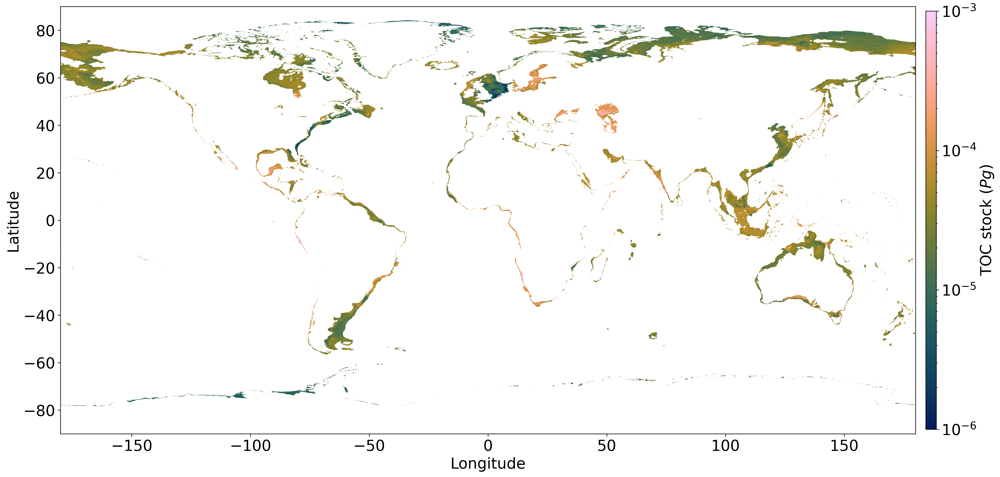

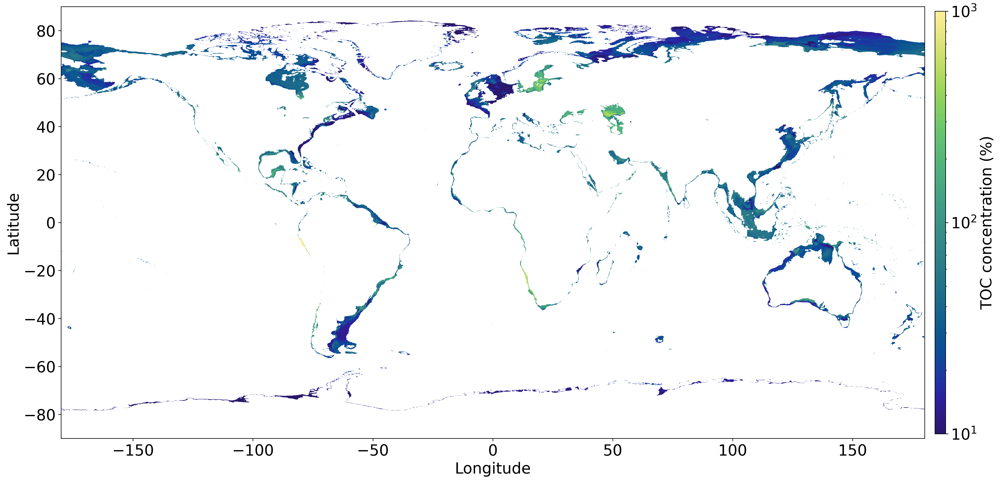

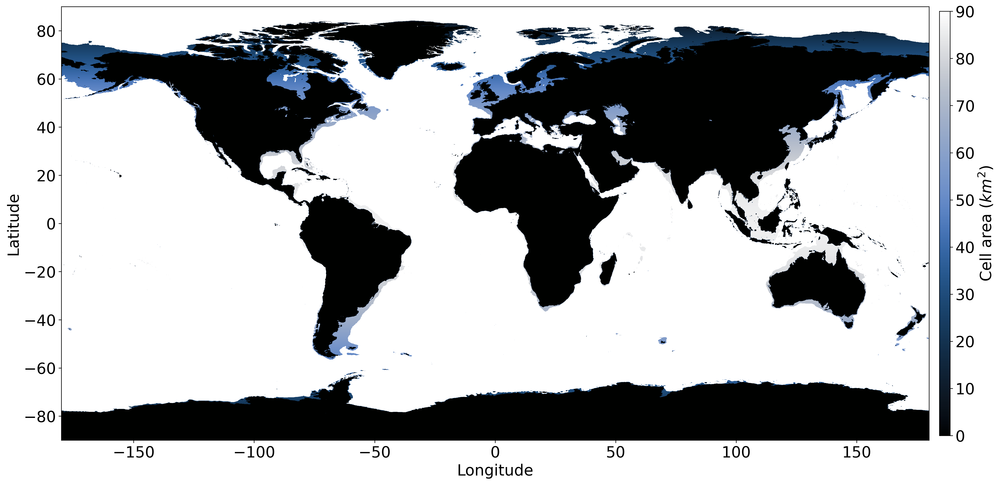

In [81]:
# get the toc map for the continental shelves
dataset_mask = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/masks/mask_deepocean.npy")
dataset_mask = np.rot90(np.rot90(np.fliplr(dataset_mask)))

# Create a copy of tocGlobal_CS
tocGlobal_g_CS_masked = np.copy(tocGlobal_g)
# Use boolean indexing to set values to nan where dataset_mask is not nan
tocGlobal_g_CS_masked[~np.isnan(dataset_mask)] = np.nan


tocPercent_cellwise_CS_masked = np.copy(tocPercent_cellwise)
# Use boolean indexing to set values to nan where dataset_mask is not nan
tocPercent_cellwise_CS_masked[~np.isnan(dataset_mask)] = np.nan

area_np_land_CS_masked = np.copy(area_np_land)
# Use boolean indexing to set values to nan where dataset_mask is not nan
area_np_land_CS_masked[~np.isnan(dataset_mask)] = np.nan

VisualiseMap(tocGlobal_g_CS_masked/1e15, cmap=cmc.batlow, use_log_norm=True, vmin=1e-6, vmax=1e-3, cbar_label= "TOC stock ($Pg$)")
VisualiseMap(tocPercent_cellwise_CS_masked, cmap=cmo.cm.haline, use_log_norm=True,vmin=1e1, vmax=1e3, cbar_label= "TOC concentration (%)")
VisualiseMap(area_np_land_CS_masked, cmap=cmc.oslo, vmax=90, cbar_label='Cell area ($km^2$)')


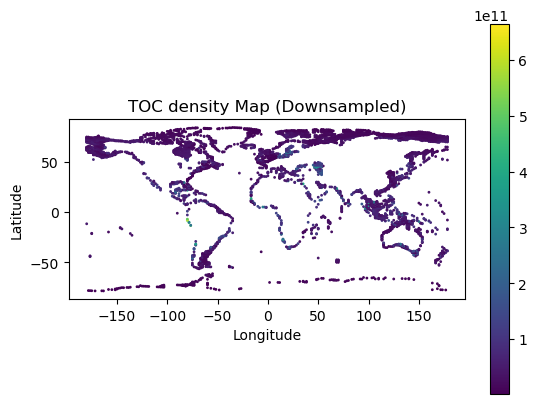

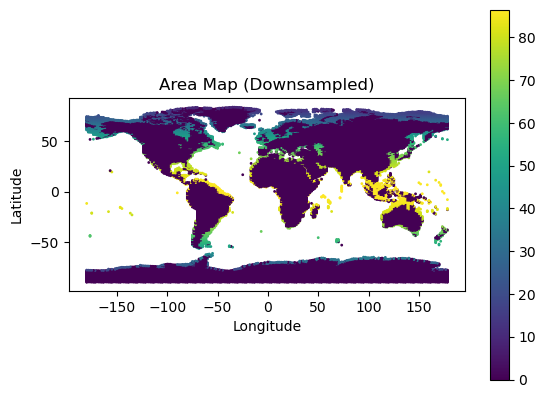

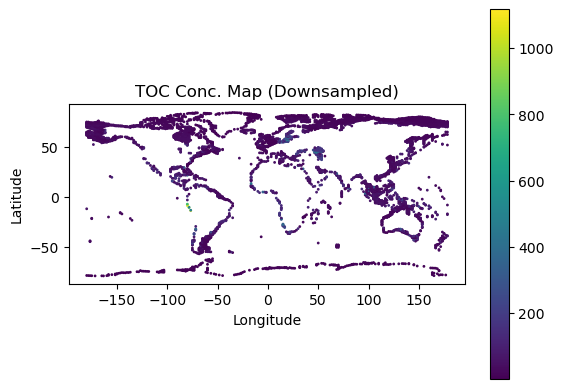

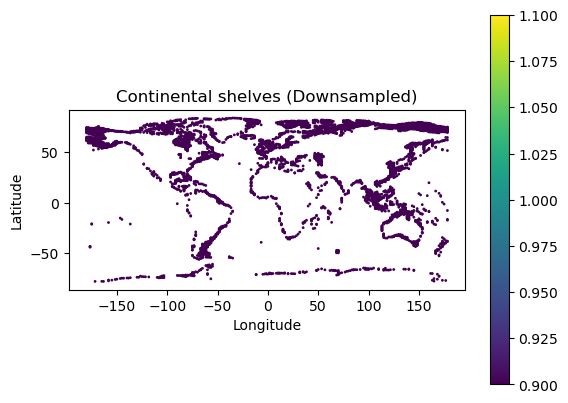

In [82]:

tocPercent_cellwise_CS_masked_rot = np.rot90(np.rot90(np.fliplr(tocPercent_cellwise_CS_masked)))
area_np_land_CS_masked_rot = np.rot90(np.rot90(np.fliplr(area_np_land_CS_masked)))
tocGlobal_g_CS_masked_rot = np.rot90(np.rot90(np.fliplr(tocGlobal_g_CS_masked)))
# Create a GeoDataFrame with the prediction values and their corresponding geometry
lon_mesh, lat_mesh = np.meshgrid(lon, lat)
tocPercentcCellwise_CS_masked_gdf = gpd.GeoDataFrame(
    data={'TOCPercent': tocPercent_cellwise_CS_masked_rot.flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)
prediction_CS_masked_gdf = gpd.GeoDataFrame(
    data={'TOC': tocGlobal_g_CS_masked_rot.flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)
area_CS_masked_gdf = gpd.GeoDataFrame(
    data={'area': np.array(area_np_land_CS_masked_rot).flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)
continentalshelves_gdf = gpd.GeoDataFrame(
    data={'continentalshelves': np.array(continentalshelves_mask).flatten()},
    geometry=gpd.points_from_xy(lon_mesh.flatten(), lat_mesh.flatten()),
    crs='EPSG:4326'
)


# Downsample the GeoDataFrame by taking every nth point
n = 100  # Adjust this value based on your desired level of downsampling
downsampled_gdf = prediction_CS_masked_gdf.iloc[::n, :]

# Plot the downsampled GeoDataFrame
downsampled_gdf.plot(column='TOC', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('TOC density Map (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

downsampled_gdf = area_CS_masked_gdf.iloc[::n, :]

# Plot the downsampled GeoDataFrame
downsampled_gdf.plot(column='area', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('Area Map (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

downsampled_gdf = tocPercentcCellwise_CS_masked_gdf.iloc[::n, :]

downsampled_gdf.plot(column='TOCPercent', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('TOC Conc. Map (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

downsampled_gdf = continentalshelves_gdf.iloc[::n, :]

downsampled_gdf.plot(column='continentalshelves', cmap='viridis', legend=True, markersize=1)

# Add title and labels
plt.title('Continental shelves (Downsampled)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Show the plot
plt.show()

In [83]:
# Perform a spatial join to associate each point with the corresponding polygon
joined_gdf = gpd.sjoin(prediction_CS_masked_gdf, ocean_comarge_gdf, predicate='within')
joined_area_gdf = gpd.sjoin(area_CS_masked_gdf, ocean_comarge_gdf, predicate='within')
# Perform a spatial join to associate each point with the corresponding polygon
joined_gdf_TOCPercent = gpd.sjoin(tocPercentcCellwise_CS_masked_gdf, ocean_comarge_gdf, predicate='within')

In [84]:
# Calculate the sum of TOC in each polygon
sum_toc_by_polygon = (joined_gdf.groupby('name')['TOC']).sum()

# Print the sum of TOC in each polygon
for ocean_name, toc_sum in sum_toc_by_polygon.items():
    print(f"Sum of TOC between 140m and 200m of {ocean_name}: {toc_sum/1e15} Pg")

Sum of TOC between 140m and 200m of Arctic Ocean: 0.4639243905086056 Pg
Sum of TOC between 140m and 200m of Indian Ocean: 0.3092855230363213 Pg
Sum of TOC between 140m and 200m of Mediterranean Region: 0.08959487738671912 Pg
Sum of TOC between 140m and 200m of North Atlantic Ocean: 0.40965853237572464 Pg
Sum of TOC between 140m and 200m of North Pacific Ocean: 0.5793479236645385 Pg
Sum of TOC between 140m and 200m of South Atlantic Ocean: 0.4281814187310979 Pg
Sum of TOC between 140m and 200m of South China and Easter Archipelagic Seas: 0.23309673153806548 Pg
Sum of TOC between 140m and 200m of South Pacific Ocean: 0.44658506708671664 Pg
Sum of TOC between 140m and 200m of Southern Ocean: 0.003992564986603304 Pg


In [85]:
# Calculate the sum of TOC in each polygon
sum_toc_by_polygon = (joined_gdf_TOCPercent.groupby('name')['TOCPercent']).sum()

# Print the sum of TOC in each polygon
for ocean_name, toc_sum in sum_toc_by_polygon.items():
    print(f"Sum of TOC % between 140m and 200m of {ocean_name}: {toc_sum/1e6} %km^2 (1e6)")

Sum of TOC % between 140m and 200m of Arctic Ocean: 0.45322863520577167 %km^2 (1e6)
Sum of TOC % between 140m and 200m of Indian Ocean: 0.28947777802375285 %km^2 (1e6)
Sum of TOC % between 140m and 200m of Mediterranean Region: 0.08557350972153684 %km^2 (1e6)
Sum of TOC % between 140m and 200m of North Atlantic Ocean: 0.3851712671449188 %km^2 (1e6)
Sum of TOC % between 140m and 200m of North Pacific Ocean: 0.5384326351588711 %km^2 (1e6)
Sum of TOC % between 140m and 200m of South Atlantic Ocean: 0.6003365874484393 %km^2 (1e6)
Sum of TOC % between 140m and 200m of South China and Easter Archipelagic Seas: 0.23326676884376116 %km^2 (1e6)
Sum of TOC % between 140m and 200m of South Pacific Ocean: 0.6096565643812643 %km^2 (1e6)
Sum of TOC % between 140m and 200m of Southern Ocean: 0.00485530930721608 %km^2 (1e6)


In [86]:
# Calculate the sum of TOC in each polygon
area_by_polygon = (joined_area_gdf.groupby('name')['area']).sum()

# Print the sum of TOC in each polygon
for ocean_name, area in area_by_polygon.items():
    print(f"Area of  between 140m and 200m of {ocean_name}: {area/1e6} million km^2")

Area of  between 140m and 200m of Arctic Ocean: 0.54035575 million km^2
Area of  between 140m and 200m of Indian Ocean: 0.42771375 million km^2
Area of  between 140m and 200m of Mediterranean Region: 0.132304671875 million km^2
Area of  between 140m and 200m of North Atlantic Ocean: 0.5686653125 million km^2
Area of  between 140m and 200m of North Pacific Ocean: 0.7348725625 million km^2
Area of  between 140m and 200m of South Atlantic Ocean: 0.3923725 million km^2
Area of  between 140m and 200m of South China and Easter Archipelagic Seas: 0.35215096875 million km^2
Area of  between 140m and 200m of South Pacific Ocean: 0.34091159375 million km^2
Area of  between 140m and 200m of Southern Ocean: 0.0115087109375 million km^2


In [87]:
# Calculate the mean TOC percent for each polygon
mean_toc_percent_by_polygon = sum_toc_by_polygon / area_by_polygon

# Print the mean TOC percent in each polygon
for ocean_name, mean_toc_percent in mean_toc_percent_by_polygon.items():
    print(f"Mean TOC Percent between 140m and 200m of {ocean_name}: {mean_toc_percent} %")

Mean TOC Percent between 140m and 200m of Arctic Ocean: 0.83875971562396 %
Mean TOC Percent between 140m and 200m of Indian Ocean: 0.6768025999251903 %
Mean TOC Percent between 140m and 200m of Mediterranean Region: 0.6467912924676291 %
Mean TOC Percent between 140m and 200m of North Atlantic Ocean: 0.677325060414897 %
Mean TOC Percent between 140m and 200m of North Pacific Ocean: 0.7326884450919625 %
Mean TOC Percent between 140m and 200m of South Atlantic Ocean: 1.530016979906694 %
Mean TOC Percent between 140m and 200m of South China and Easter Archipelagic Seas: 0.6624055860807884 %
Mean TOC Percent between 140m and 200m of South Pacific Ocean: 1.78831279298862 %
Mean TOC Percent between 140m and 200m of Southern Ocean: 0.4218812457436509 %


In [88]:
# Perform a spatial join to associate each point with the corresponding polygon
joined_gdf = gpd.sjoin(prediction_CS_masked_gdf, ocean_gdf, predicate='within')
joined_area_gdf = gpd.sjoin(area_CS_masked_gdf, ocean_gdf, predicate='within')
# Perform a spatial join to associate each point with the corresponding polygon
joined_gdf_TOCPercent = gpd.sjoin(tocPercentcCellwise_CS_masked_gdf, ocean_gdf, predicate='within')

In [89]:
# Calculate the sum of TOC in each polygon
sum_toc_by_polygon = (joined_gdf.groupby('name')['TOC']).sum()

# Print the sum of TOC in each polygon
for ocean_name, toc_sum in sum_toc_by_polygon.items():
    print(f"Sum of TOC between 0m and 200m of {ocean_name}: {toc_sum/1e15} Pg")

Sum of TOC between 0m and 200m of Arctic Ocean: 6.029375185841168 Pg
Sum of TOC between 0m and 200m of Baltic Sea: 0.9942331151030155 Pg
Sum of TOC between 0m and 200m of Indian Ocean: 2.88876395573437 Pg
Sum of TOC between 0m and 200m of Mediterranean Region: 0.6327033167892516 Pg
Sum of TOC between 0m and 200m of North Atlantic Ocean: 2.7420025299337785 Pg
Sum of TOC between 0m and 200m of North Pacific Ocean: 2.8799301767901784 Pg
Sum of TOC between 0m and 200m of South Atlantic Ocean: 1.4819311969709157 Pg
Sum of TOC between 0m and 200m of South China and Easter Archipelagic Seas: 1.9481148196689173 Pg
Sum of TOC between 0m and 200m of South Pacific Ocean: 1.4796971915129744 Pg
Sum of TOC between 0m and 200m of Southern Ocean: 0.14215350954573114 Pg


In [90]:
# Calculate the sum of TOC in each polygon
sum_toc_by_polygon = (joined_gdf_TOCPercent.groupby('name')['TOCPercent']).sum()

# Print the sum of TOC in each polygon
for ocean_name, toc_sum in sum_toc_by_polygon.items():
    print(f"Sum of TOC % between 0m and 200m of {ocean_name}: {toc_sum/1e6} %km^2 (1e6)")

Sum of TOC % between 0m and 200m of Arctic Ocean: 5.824343251178277 %km^2 (1e6)
Sum of TOC % between 0m and 200m of Baltic Sea: 1.564289291773062 %km^2 (1e6)
Sum of TOC % between 0m and 200m of Indian Ocean: 2.7469427906400994 %km^2 (1e6)
Sum of TOC % between 0m and 200m of Mediterranean Region: 0.6558966178905852 %km^2 (1e6)
Sum of TOC % between 0m and 200m of North Atlantic Ocean: 2.6242781039426664 %km^2 (1e6)
Sum of TOC % between 0m and 200m of North Pacific Ocean: 2.6855121041065697 %km^2 (1e6)
Sum of TOC % between 0m and 200m of South Atlantic Ocean: 1.769350245498118 %km^2 (1e6)
Sum of TOC % between 0m and 200m of South China and Easter Archipelagic Seas: 1.8157061415699478 %km^2 (1e6)
Sum of TOC % between 0m and 200m of South Pacific Ocean: 1.7567285175724698 %km^2 (1e6)
Sum of TOC % between 0m and 200m of Southern Ocean: 0.2355050972309542 %km^2 (1e6)


In [91]:
# Calculate the sum of TOC in each polygon
area_by_polygon = (joined_area_gdf.groupby('name')['area']).sum()

# Print the sum of TOC in each polygon
for ocean_name, area in area_by_polygon.items():
    print(f"Area of  between 0m and 200m of {ocean_name}: {area/1e6} million km^2")

Area of  between 0m and 200m of Arctic Ocean: 5.7236845 million km^2
Area of  between 0m and 200m of Baltic Sea: 0.39123490625 million km^2
Area of  between 0m and 200m of Indian Ocean: 4.06489675 million km^2
Area of  between 0m and 200m of Mediterranean Region: 0.652842625 million km^2
Area of  between 0m and 200m of North Atlantic Ocean: 4.2632085 million km^2
Area of  between 0m and 200m of North Pacific Ocean: 3.83248925 million km^2
Area of  between 0m and 200m of South Atlantic Ocean: 1.864818875 million km^2
Area of  between 0m and 200m of South China and Easter Archipelagic Seas: 2.99495775 million km^2
Area of  between 0m and 200m of South Pacific Ocean: 1.456509375 million km^2
Area of  between 0m and 200m of Southern Ocean: 0.574039 million km^2


In [92]:
# Calculate the mean TOC percent for each polygon
mean_toc_percent_by_polygon = sum_toc_by_polygon / area_by_polygon

# Print the mean TOC percent in each polygon
for ocean_name, mean_toc_percent in mean_toc_percent_by_polygon.items():
    print(f"Mean TOC Percent between 0m and 200m of {ocean_name}: {mean_toc_percent} %")

Mean TOC Percent between 0m and 200m of Arctic Ocean: 1.017586355638274 %
Mean TOC Percent between 0m and 200m of Baltic Sea: 3.998337742321687 %
Mean TOC Percent between 0m and 200m of Indian Ocean: 0.6757718484830149 %
Mean TOC Percent between 0m and 200m of Mediterranean Region: 1.0046779924803244 %
Mean TOC Percent between 0m and 200m of North Atlantic Ocean: 0.6155641001238072 %
Mean TOC Percent between 0m and 200m of North Pacific Ocean: 0.7007226710698718 %
Mean TOC Percent between 0m and 200m of South Atlantic Ocean: 0.948805414412227 %
Mean TOC Percent between 0m and 200m of South China and Easter Archipelagic Seas: 0.6062543425094887 %
Mean TOC Percent between 0m and 200m of South Pacific Ocean: 1.2061223550809412 %
Mean TOC Percent between 0m and 200m of Southern Ocean: 0.41025975104645185 %
